In [1]:
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
print(path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
/kaggle/input/telco-customer-churn


In [2]:
import os

os.listdir('/kaggle/input/telco-customer-churn')

['WA_Fn-UseC_-Telco-Customer-Churn.csv']

In [17]:
import pandas as pd

df = pd.read_csv('/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [18]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [13]:
df.head()

,SeniorCitizen,tenure,MonthlyCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,...,TotalCharges_996.45,TotalCharges_996.85,TotalCharges_996.95,TotalCharges_997.65,TotalCharges_997.75,TotalCharges_998.1,TotalCharges_999.45,TotalCharges_999.8,TotalCharges_999.9,Churn_Yes
0,0,1,29.85,False,True,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,0,34,56.95,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0,2,53.85,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,0,45,42.30,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,0,2,70.70,False,False,False,True,False,False,True,...,False,False,False,False,False,False,False,False,False,True


In [14]:
df.shape

(7043, 6560)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Columns: 6560 entries, SeniorCitizen to Churn_Yes
dtypes: bool(6557), float64(1), int64(2)
memory usage: 44.2 MB


In [7]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [8]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [19]:
df = df.dropna()

In [10]:
df.shape

(7043, 21)

In [20]:
df = df.drop('customerID', axis=1)

In [12]:
df = pd.get_dummies(df, drop_first=True)

In [21]:
df["Churn"] = df["Churn"].map({"Yes":1, "No":0})

In [24]:
df.shape
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7032 non-null   int64  
 1   tenure                                 7032 non-null   int64  
 2   MonthlyCharges                         7032 non-null   float64
 3   TotalCharges                           7032 non-null   float64
 4   Churn                                  7032 non-null   int64  
 5   gender_Male                            7032 non-null   bool   
 6   Partner_Yes                            7032 non-null   bool   
 7   Dependents_Yes                         7032 non-null   bool   
 8   PhoneService_Yes                       7032 non-null   bool   
 9   MultipleLines_No phone service         7032 non-null   bool   
 10  MultipleLines_Yes                      7032 non-null   bool   
 11  InternetS

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [23]:
categorical_cols = df.select_dtypes(include=['object']).columns
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [25]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [26]:
X.shape
y.shape

(7032,)

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [29]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [30]:
y_pred = model.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print(classification_report(y_test, y_pred))

Accuracy: 0.7917555081734187
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.65      0.48      0.55       374

    accuracy                           0.79      1407
   macro avg       0.74      0.69      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [32]:
import pandas as pd

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance.head(10)

,0
TotalCharges,0.195802
MonthlyCharges,0.168231
tenure,0.167302
InternetService_Fiber optic,0.038661
PaymentMethod_Electronic check,0.035773
Contract_Two year,0.029693
gender_Male,0.027900
OnlineSecurity_Yes,0.027197
PaperlessBilling_Yes,0.024655
TechSupport_Yes,0.024462


In [33]:
!pip install shap

In [34]:
import shap

In [35]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

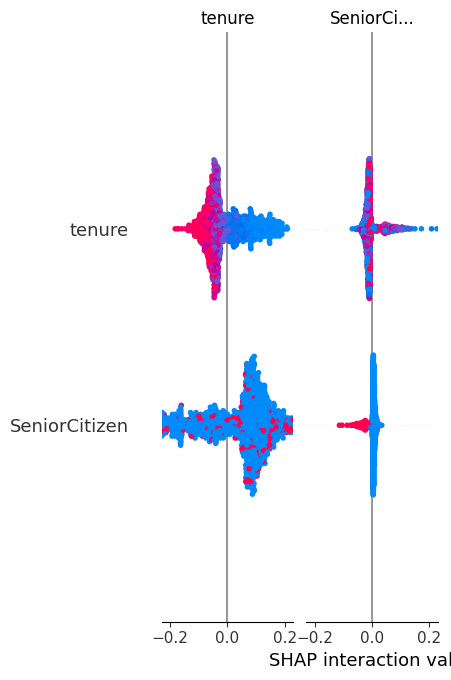

In [36]:
shap.summary_plot(shap_values, X_test)

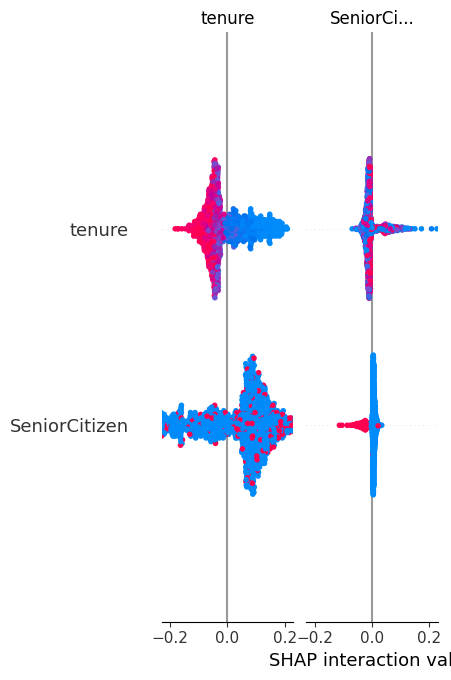

In [44]:
import matplotlib.pyplot as plt
import shap

shap.summary_plot(shap_values, X_test, show=False)
plt.savefig("shap_summary.png", bbox_inches="tight")

In [45]:
import pandas as pd

feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance.head(10)

,0
TotalCharges,0.195802
MonthlyCharges,0.168231
tenure,0.167302
InternetService_Fiber optic,0.038661
PaymentMethod_Electronic check,0.035773
Contract_Two year,0.029693
gender_Male,0.027900
OnlineSecurity_Yes,0.027197
PaperlessBilling_Yes,0.024655
TechSupport_Yes,0.024462


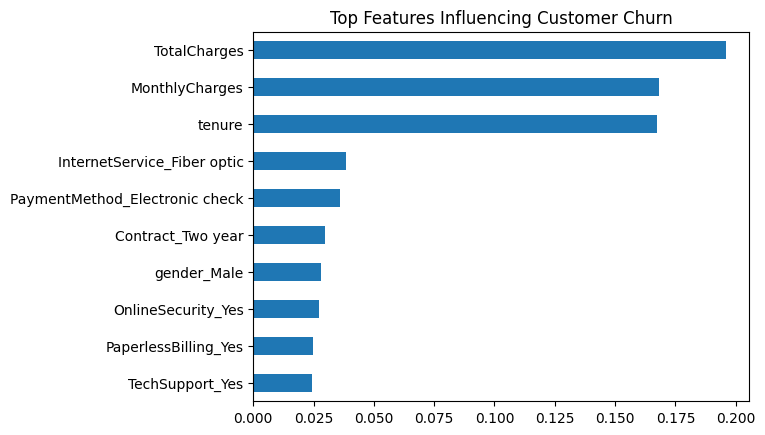

In [46]:
feature_importance.head(10).plot(kind="barh")
plt.title("Top Features Influencing Customer Churn")
plt.gca().invert_yaxis()
plt.savefig("feature_importance.png", bbox_inches="tight")


In [47]:
content = """
# Business Insights from Customer Churn Analysis

This analysis uses machine learning and explainable AI (SHAP) to identify the key factors influencing customer churn in a telecommunications company.

## Key Business Insights

### 1. Customer tenure is a strong predictor of churn
Customers who have been with the company for a shorter period are significantly more likely to leave.
This suggests that the early stages of the customer lifecycle are critical.

### 2. Higher monthly charges increase churn probability
Customers paying higher monthly fees tend to have a higher probability of leaving the service.

### 3. Long-term contracts reduce churn risk
Customers with two-year contracts show a much lower churn probability compared to month-to-month plans.

### 4. Fiber optic internet users exhibit higher churn risk
Customers subscribed to fiber optic internet services appear more likely to churn.

### 5. Additional support services reduce churn probability
Customers who subscribe to services such as technical support or online security generally show lower churn rates.
"""

with open("business_insights.md", "w") as f:
    f.write(content)

print("File created!")

File created!


In [48]:
req = """
pandas
numpy
scikit-learn
shap
matplotlib
"""

with open("requirements.txt", "w") as f:
    f.write(req)

In [49]:
readme = """
# Customer Churn Prediction with Explainable AI

This project demonstrates how machine learning and SHAP explainability can be used to analyze customer churn.

## Dataset
Telco Customer Churn dataset from Kaggle.

## Model
Random Forest classifier.

## Explainability
SHAP was used to identify the most important drivers of churn.

## Business Insights
Key factors influencing churn include tenure, monthly charges, and contract type.
"""

with open("README.md", "w") as f:
    f.write(readme)